# Who gets the carbon dividend?

Name: Jami Haavisto

**Recommendation for the finance minister**

**Adopt a targeted dividend to protect lower-income and rural households.**

Give one allocation weight to urban D1–D5 (income deciles 1-5, measured by person) and rural D6–D10, two to rural D1–D5, and none to urban D6–D10. Table 1 shows the trade-off: rural D1–D5 move from an average net cost of EUR 137 under equal dividends to a EUR 634 net gain; urban D6–D10 move from an EUR 86 net gain to a EUR 489 net cost. Figure 1 shows household variation and the eligibility boundary for urban households above D5. I recommend this shift because rural lower-income households are especially exposed under the equal rule, while high-income urban households may have more options to invest in efficient heating or low-emission transportation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

h = pd.read_csv(Path("households.csv"))
h["tax"] = 100 * (h["heat_t"] + h["travel_t"])
revenue = h["tax"].sum()
h["equal_dividend"] = revenue / len(h)
h["net_equal"] = h["tax"] - h["equal_dividend"]
print(f"{len(h)} households | Revenue EUR {revenue:,.2f} | Equal dividend EUR {revenue / len(h):,.2f}")
print("Equal-rule unallocated revenue (EUR):", round(revenue - h["equal_dividend"].sum(), 6))
assert abs(revenue - h["equal_dividend"].sum()) < 0.01

240 households | Revenue EUR 137,916.00 | Equal dividend EUR 574.65
Equal-rule unallocated revenue (EUR): 0.0


### Your economic priority and policy rule

**Priority:** protect lower- and middle-income households, while giving additional support to rural households. Household income is measured per person (`income_eur / people`). The first five income deciles (the lower half of households) qualify regardless of area. Every rural household also qualifies, including those in deciles 6–10. Urban households in deciles 6–10 receive no dividend.

The proposal assigns a weight of 1 to qualifying urban households, 1 to rural households in deciles 6–10, and 2 to rural households in deciles 1–5. The dividend pool is distributed in proportion to these weights, so a rural household in the lower half receives twice the weight of an otherwise eligible household with weight 1. All households face the same emissions tax; eligibility and weights use pre-policy income and residence.

In [2]:
# Allocate the full revenue in proportion to nonnegative household weights.
def distribute(weights):
    weights = pd.Series(weights, index=h.index, dtype=float)
    assert np.isfinite(weights).all() and (weights >= 0).all() and weights.sum() > 0
    return revenue * weights / weights.sum()

# Assign income deciles using household income per person.
# Each row represents one equally weighted household; rank breaks any exact ties consistently.
h["income_per_person"] = h["income_eur"] / h["people"]
h["income_decile"] = pd.qcut(
    h["income_per_person"].rank(method="first"), q=10, labels=False
) + 1
h["lower_middle_half"] = h["income_decile"] <= 5

# No universal base payment: urban D6-D10 have weight 0.
# Rural households qualify at every income level; rural D1-D5 receive an extra weight.
h["policy_weight"] = np.where(
    h["area"].eq("Rural"),
    1 + h["lower_middle_half"].astype(int),
    h["lower_middle_half"].astype(int),
)
h["proposal"] = distribute(h["policy_weight"])
h["net_proposal"] = h["tax"] - h["proposal"]

print("Income-decile household counts:")
print(h.groupby("income_decile", observed=True).size().to_string())
print("\nHouseholds with positive dividend weight:", int((h["policy_weight"] > 0).sum()))
print("Proposed-rule unallocated revenue (EUR):", round(revenue - h["proposal"].sum(), 6))
assert h["proposal"].notna().all() and (h["proposal"] >= 0).all()
assert abs(h["proposal"].sum() - revenue) < 0.01

Income-decile household counts:
income_decile
1     24
2     24
3     24
4     24
5     24
6     24
7     24
8     24
9     24
10    24

Households with positive dividend weight: 159
Proposed-rule unallocated revenue (EUR): 0.0


In [3]:
# Budget and nonnegative-dividend checks for the proposed rule.
print("Proposed-rule unallocated revenue (EUR):", round(revenue - h["proposal"].sum(), 6))
assert h["proposal"].notna().all() and (h["proposal"] >= 0).all()
assert abs(h["proposal"].sum() - revenue) < 0.01

Proposed-rule unallocated revenue (EUR): 0.0


### Table

**Table 1. Mean household net cost under equal and targeted dividends, by income half and area.** Groups are defined by household income per person: D1–D5 (lower/middle half) and D6–D10 (upper half), crossed with urban/rural residence. Net cost is tax minus dividend; positive values mean a net payment and negative values a net gain. The percentage outcome is each household's net cost divided by its own annual household income, averaged within the group. Each row in the data has equal weight.

The table reports group size and mean outcomes under both dividend rules. Values are rounded for display only.

In [4]:
# Compare group sizes and average household outcomes under both dividend rules.
h["income_group"] = pd.Categorical(
    np.where(
        h["income_decile"] <= 5,
        "D1-D5 (lower/middle half)",
        "D6-D10 (upper half)",
    ),
    categories=["D1-D5 (lower/middle half)", "D6-D10 (upper half)"],
    ordered=True,
)
h["area"] = pd.Categorical(h["area"], categories=["Urban", "Rural"], ordered=True)
h["net_equal_pct"] = 100 * h["net_equal"] / h["income_eur"]
h["net_proposal_pct"] = 100 * h["net_proposal"] / h["income_eur"]

summary = (
    h.groupby(["income_group", "area"], observed=True, sort=True)
    .agg(
        households=("id", "size"),
        equal_mean_net_eur=("net_equal", "mean"),
        proposal_mean_net_eur=("net_proposal", "mean"),
        equal_mean_net_pct_income=("net_equal_pct", "mean"),
        proposal_mean_net_pct_income=("net_proposal_pct", "mean"),
    )
    .rename(columns={
        "households": "Households (n)",
        "equal_mean_net_eur": "Equal: mean net cost (EUR/household)",
        "proposal_mean_net_eur": "Targeted: mean net cost (EUR/household)",
        "equal_mean_net_pct_income": "Equal: mean net cost (% own income)",
        "proposal_mean_net_pct_income": "Targeted: mean net cost (% own income)",
    })
)
summary["Households (n)"] = summary["Households (n)"].astype(int)
print("Table 1. Mean net cost under each dividend rule")
display(summary.round(1))

Table 1. Mean net cost under each dividend rule


Households (n)  \
income_group              area                    
D1-D5 (lower/middle half) Urban              74   
                          Rural              46   
D6-D10 (upper half)       Urban              81   
                          Rural              39   

                                 Equal: mean net cost (EUR/household)  \
income_group              area                                          
D1-D5 (lower/middle half) Urban                                 -59.0   
                          Rural                                 136.7   
D6-D10 (upper half)       Urban                                 -86.0   
                          Rural                                 129.3   

                                 Targeted: mean net cost (EUR/household)  \
income_group              area                                             
D1-D5 (lower/middle half) Urban                                   -157.1   
                          Rural                                   -634.2   
D6-D10 (upper half)       Urban                                    488.7   
                          Rural                                     31.2   

                                 Equal: mean net cost (% own income)  \
income_group              area                                         
D1-D5 (lower/middle half) Urban                                 -0.3   
                          Rural                                  0.4   
D6-D10 (upper half)       Urban                                 -0.4   
                          Rural                                  0.3   

                                 Targeted: mean net cost (% own income)  
income_group              area                                           
D1-D5 (lower/middle half) Urban                                    -0.6  
                          Rural                                    -2.2  
D6-D10 (upper half)       Urban                                     1.0  
                          Rural                                     0.0

### Figure

**Net costs vary within income groups and by area.** Each point is one household. The y-axis is tax minus dividend as a percentage of that household's annual income: values above zero mean a net payment, and values below zero mean a net gain. The vertical dashed line marks the boundary between income deciles 5 and 6. Comparing the panels shows how the targeted rule changes the spread of household outcomes and the treatment of urban households above the cutoff. Emissions and incomes are held fixed for this first-year comparison.

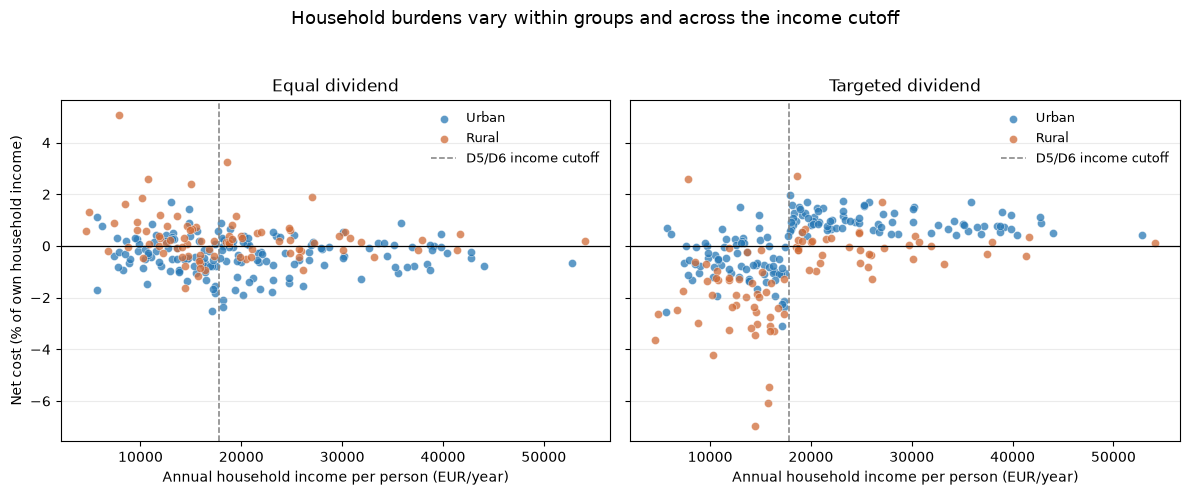

In [5]:
# Household-level distribution: compare both rules and expose the D5/D6 boundary.
h["net_equal_pct"] = 100 * h["net_equal"] / h["income_eur"]
h["net_proposal_pct"] = 100 * h["net_proposal"] / h["income_eur"]
cutoff = (
    h.loc[h["income_decile"].eq(5), "income_per_person"].max()
    + h.loc[h["income_decile"].eq(6), "income_per_person"].min()
) / 2

area_colors = {"Urban": "#2878B5", "Rural": "#D06B37"}
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, outcome, title in zip(
    axes,
    ["net_equal_pct", "net_proposal_pct"],
    ["Equal dividend", "Targeted dividend"],
):
    for area, color in area_colors.items():
        group = h[h["area"] == area]
        ax.scatter(
            group["income_per_person"],
            group[outcome],
            s=34,
            alpha=0.75,
            color=color,
            edgecolors="white",
            linewidths=0.35,
            label=area,
        )
    ax.axhline(0, color="black", linewidth=0.9)
    ax.axvline(
        cutoff,
        color="gray",
        linestyle="--",
        linewidth=1.1,
        label="D5/D6 income cutoff",
    )
    ax.set_title(title)
    ax.set_xlabel("Annual household income per person (EUR/year)")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(frameon=False, fontsize=9)

axes[0].set_ylabel("Net cost (% of own household income)")
fig.suptitle("Household burdens vary within groups and across the income cutoff", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

### Challenge and AI

**Sensitivity test: Is support for the upper part of the lower-income half justified?** As a stricter alternative, retain support for all rural households but limit the additional low-income weight to D1–D3 rather than D1–D5. This keeps the rural priority and shifts more of the fixed budget toward the bottom three deciles. It is a test of the rule, not proof of who is genuinely in need: the data do not measure household liquidity, assets, or ability to invest in lower-emission heating and transport.

In the data, the 29 urban households in D4–D5 receive an average EUR 673 dividend under the main rule. Their average net cost changes from **−0.9% to +1.3% of household income** under the stricter alternative. For D1–D3 overall, average net cost changes from **−0.9% to −1.8%**. The smaller total weight pool also unintentionally raises the rural D6–D10 dividend from EUR 673 to EUR 878.

I would retain D1–D5 as the main rule because it reflects the stated aim to include lower- and middle-income households (for simplicity and policy support), while treating this boundary as a genuine policy choice rather than evidence that every D4–D5 household needs support (which is very strongly challenged in the literature).

**AI check:** AI suggested testing the stricter income cutoff, based on my thoughts if the middle-income households would really need this kind of support. I recalculated the budget-balanced rule and group net costs, but decided to keep D1–D5 because my stated priority includes middle-income households.


In [6]:
# Recalculate the same revenue under a stricter income test.
# All rural households retain weight 1; only D1-D3 receive the low-income bonus.
bottom_30 = h["income_decile"] <= 3
h["challenge_weight"] = np.where(
    h["area"].eq("Rural"),
    1 + bottom_30.astype(int),
    bottom_30.astype(int),
)
h["challenge_dividend"] = distribute(h["challenge_weight"])
h["net_challenge"] = h["tax"] - h["challenge_dividend"]
h["net_challenge_pct"] = 100 * h["net_challenge"] / h["income_eur"]
h["challenge_income_band"] = pd.Categorical(
    np.select(
        [h["income_decile"] <= 3, h["income_decile"] <= 5],
        ["D1-D3", "D4-D5"],
        default="D6-D10",
    ),
    categories=["D1-D3", "D4-D5", "D6-D10"],
    ordered=True,
)

challenge_summary = (
    h.groupby(["challenge_income_band", "area"], observed=True, sort=True)
    .agg(
        households=("id", "size"),
        main_mean_dividend_eur=("proposal", "mean"),
        strict_mean_dividend_eur=("challenge_dividend", "mean"),
        main_mean_net_pct_income=("net_proposal_pct", "mean"),
        strict_mean_net_pct_income=("net_challenge_pct", "mean"),
    )
    .rename(columns={
        "households": "Households (n)",
        "main_mean_dividend_eur": "Main: mean dividend (EUR/household)",
        "strict_mean_dividend_eur": "D1-D3 test: mean dividend (EUR/household)",
        "main_mean_net_pct_income": "Main: mean net cost (% own income)",
        "strict_mean_net_pct_income": "D1-D3 test: mean net cost (% own income)",
    })
)
challenge_summary["Households (n)"] = challenge_summary["Households (n)"].astype(int)
print("Challenge: narrower low-income eligibility; all revenue remains allocated")
print("Main-rule unallocated revenue (EUR):", round(revenue - h["proposal"].sum(), 6))
print("D1-D3-test unallocated revenue (EUR):", round(revenue - h["challenge_dividend"].sum(), 6))
display(challenge_summary.round(1))

Challenge: narrower low-income eligibility; all revenue remains allocated
Main-rule unallocated revenue (EUR): 0.0
D1-D3-test unallocated revenue (EUR): 0.0


Households (n)  \
challenge_income_band area                    
D1-D3                 Urban              45   
                      Rural              27   
D4-D5                 Urban              29   
                      Rural              19   
D6-D10                Urban              81   
                      Rural              39   

                             Main: mean dividend (EUR/household)  \
challenge_income_band area                                         
D1-D3                 Urban                                672.8   
                      Rural                               1345.5   
D4-D5                 Urban                                672.8   
                      Rural                               1345.5   
D6-D10                Urban                                  0.0   
                      Rural                                672.8   

                             D1-D3 test: mean dividend (EUR/household)  \
challenge_income_band area                                               
D1-D3                 Urban                                      878.4   
                      Rural                                     1756.9   
D4-D5                 Urban                                        0.0   
                      Rural                                      878.4   
D6-D10                Urban                                        0.0   
                      Rural                                      878.4   

                             Main: mean net cost (% own income)  \
challenge_income_band area                                        
D1-D3                 Urban                                -0.5   
                      Rural                                -1.7   
D4-D5                 Urban                                -0.9   
                      Rural                                -2.9   
D6-D10                Urban                                 1.0   
                      Rural                                 0.0   

                             D1-D3 test: mean net cost (% own income)  
challenge_income_band area                                             
D1-D3                 Urban                                      -1.1  
                      Rural                                      -3.0  
D4-D5                 Urban                                       1.3  
                      Rural                                      -1.2  
D6-D10                Urban                                       1.0  
                      Rural                                      -0.5